# Curso: Redes Neurais Convolucionais

Prof. [Denilson Alves Pereira](https://sites.google.com/ufla.br/denilsonpereira) <br>
Departamento de Ciência da Computação (DCC) <br>
Instituto de Ciências Exatas e Tecnológicas (ICET) <br> 
Universidade Federal de Lavras (UFLA)

## Classificação de Imagens

Objetivo: apresentar um exemplo de aplicação de rede neural convolucional para classificação de imagens.

Você vai aprender a:
- Ler arquivos de imagens no formato .csv e convertê-los para vetores de pixels
- Utilizar um gerador de dados aumentados para expandir o conjunto de imagens para treinamento da rede
- Configurar uma rede neural com camadas de convolução, pooling e densa para um problema de classificação multiclasse de imagens

Versão: Julho, 2021

### Representação de imagens RGB

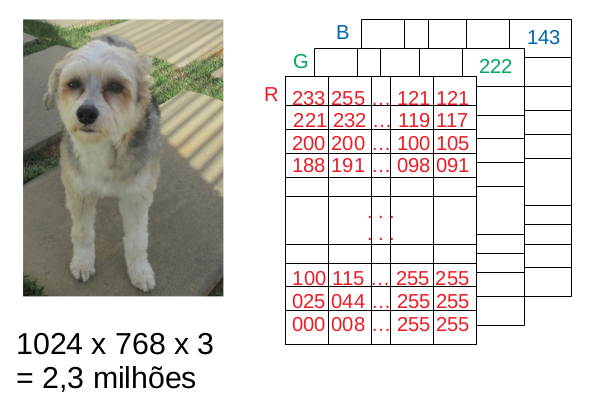

Em imagens coloridas, o padrão RGB (Red, Green, Blue) representa cada pixel como um vetor de três números para os três canais das cores primárias vermelho, verde e azul. Cada número varia de 0 a 255, representando a intensidade da cor correspondente. O três valores combinados formam a cor do pixel. Por exemplo, a cor violeta pode ser representada como 128, 0, 128, uma mistura de intensidade moderada de vermelho e azul, sem o verde.

Já em imagens em escala de cinza (*grayscale*), cada pixel é representado com um único número (entre 0 e 255), o qual determina o quão preto é o pixel (0 é preto e 255 é branco brilhante).

## O Problema a ser Resolvido

O objetivo da atividade é elaborar uma rede neural convolucional para predizer o dígito (um número de 0 a 9) manuscrito em uma imagem. <br>

Será usado o MNIST dataset, disponível em https://www.kaggle.com/oddrationale/mnist-in-csv. Ele possui 60.000 exemplos para treino e 10.000 para teste. O arquivo já foi processado do dataset original, e cada linha consiste de 785 valores: o primeiro valor é o rótulo (um número de 0 a 9) e os 784 restantes são os valores dos pixels (um número de 0 a 255). Isso significa que a imagem está representada no formato de um vetor "achatado" (*flatten*), onde cada imagem tem o tamanho 28 x 28 (totalizando os 784 pixels), em escala de cinza.

## Pacotes

In [1]:
import numpy as np # scientific computing
import tensorflow as tf  #  numerical computation using data flow graphs
from tensorflow import keras  # deep learning
from keras_preprocessing.image import ImageDataGenerator, load_img  # generate batches of tensor image data with real-time data augmentation
import pandas as pd # structured data
import matplotlib.pyplot as plt # scientific plotting library
from sklearn.model_selection import train_test_split  # split data for training and test
import random  # pseudo-random number generators

## Inicializações

In [2]:
IMAGE_HEIGHT = 28 # altura da imagem
IMAGE_WIDTH  = 28  # largura da imagem
IMAGE_SIZE   = (IMAGE_HEIGHT, IMAGE_WIDTH) # tamanho da imagem
IMAGE_CHANNELS = 1  # número de canais da imagem

## Pré-Processamento dos Dados de Treino e de Teste

In [3]:
# Read dataset
train_data = pd.read_csv('./datasets/mnist_train.csv')
test_data  = pd.read_csv('./datasets/mnist_test.csv')

In [4]:
# Separate the class from other attributes
Y_train = train_data["label"]
X_train = train_data.drop("label", axis=1)
Y_test = test_data["label"]
X_test = test_data.drop("label", axis=1)
del train_data
del test_data

In [5]:
X_train.head()

,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,1x10,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
# number of digits in each category
Y_train.value_counts()

1    6742
7    6265
3    6131
2    5958
9    5949
0    5923
6    5918
8    5851
4    5842
5    5421
Name: label, dtype: int64

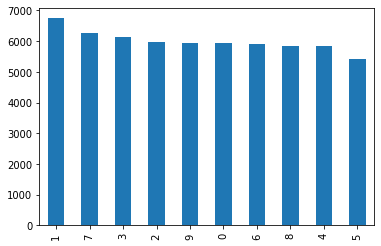

In [7]:
Y_train.value_counts().plot.bar()

In [8]:
# number of digits in each category
Y_test.value_counts()

1    1135
2    1032
7    1028
3    1010
9    1009
4     982
0     980
8     974
6     958
5     892
Name: label, dtype: int64

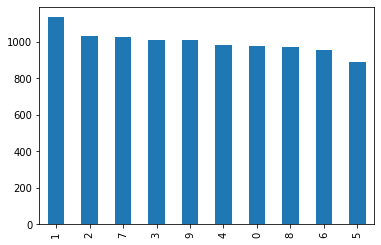

In [9]:
Y_test.value_counts().plot.bar()

In [10]:
# Normalize the data
X_train = X_train / 255.0
X_test  = X_test  / 255.0

#### Reformata as imagens

A imagem lida está no formato de um vetor "achatado" (flatten), representada por um vetor de 784 pixels. O código abaixo reformata a imagem, deixando-a no formato (28,28,1), para ser usada como entrada da rede. Keras exige esse formato, mesmo quando a imagem tem apenas um canal.

In [11]:
X_train = X_train.values.reshape(-1,IMAGE_HEIGHT,IMAGE_WIDTH,1)
X_test  = X_test.values.reshape (-1,IMAGE_HEIGHT,IMAGE_WIDTH,1)

#### Exibe uma amostra

Text(0.5, 1.0, '6')

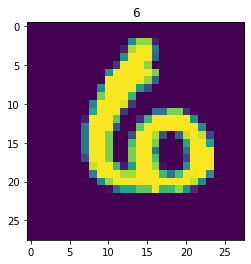

In [12]:
# Randomly chooses a file and displays its image
sample = random.randint(0,60000)
plt.imshow(X_train[sample][:,:,0])
plt.title(Y_train[sample])

#### Codifica os rótulos

Codifica os rótulos no formato *one hot encoding* <br>
Dígito 0 --> [1,0,0,0,0,0,0,0,0,0] <br>
Dígito 1 --> [0,1,0,0,0,0,0,0,0,0] <br>
Dígito 2 --> [0,0,1,0,0,0,0,0,0,0] <br>
...<br>
Dígito 9 --> [0,0,0,0,0,0,0,0,0,1] <br>

In [13]:
Y_train = tf.keras.utils.to_categorical(Y_train, num_classes = 10)
Y_test  = tf.keras.utils.to_categorical(Y_test, num_classes = 10)

In [14]:
Y_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], dtype=float32)

### Data Augmentation

*Data Augmentation* (aumento de dados) é uma técnica usada para expandir artificialmente o conjunto de dados de treinamento. Ela ajuda a evitar o problema de *overfitting*, que faz com que o modelo de treinamento fique muito ajustado aos dados usados para o treinamento, e não gera um bom desempenho em outros conjuntos de dados.

No caso das imagens de dígitos manuscrito, a ideia é alterar os dados de treino com pequenas transformações nas imagens, de forma a reproduzir as variações que ocorrem quando alguém escreve um número manualmente. Por exemplo, centralização, diferentes escalas (números grandes e pequenos), a imagem está rotacionada etc.

As abordagens para *data augmentation* alteram os dados de treino de forma a mudar a representação vetorial, mas mantendo o mesmo rótulo de classe. Algumas transformações populares são: grayscales, horizontal flips, vertical flips, random crops, color jitters, translations, rotations.

Fazendo algumas dessas transformações nos dados de treino, é possível multiplicar o número de exemplos de treino, de forma a criar um modelo mais robusto.

Tutorial para configurar *data augmentation* de imagens em Keras: https://machinelearningmastery.com/how-to-configure-image-data-augmentation-when-training-deep-learning-neural-networks/

### Generador de Treino

Documentação: https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator

Este exemplo foi adaptado de https://www.kaggle.com/yassineghouzam/introduction-to-cnn-keras-0-997-top-6.

Você não deve aplicar flips verticais e horizontais nesse tipo de imagem, pois isso poderia conduzir uma classificação incorreta de números simétricos como o 6 e 9.

In [15]:
batch_size = 15  # number of images to be generated
train_datagen = ImageDataGenerator(
        featurewise_center=False,  # set input mean to 0 over the dataset
        samplewise_center=False,  # set each sample mean to 0
        featurewise_std_normalization=False,  # divide inputs by std of the dataset
        samplewise_std_normalization=False,  # divide each input by its std
        zca_whitening=False,  # apply ZCA whitening
        rotation_range=10,  # randomly rotate images in the range (degrees, 0 to 180)
        zoom_range = 0.1, # Randomly zoom image 
        width_shift_range=0.1,  # randomly shift images horizontally (fraction of total width)
        height_shift_range=0.1,  # randomly shift images vertically (fraction of total height)
        horizontal_flip=False,  # randomly flip images
        vertical_flip=False  # randomly flip images
)

train_generator = train_datagen.flow(X_train, Y_train, batch_size=batch_size)

## Definição do Modelo

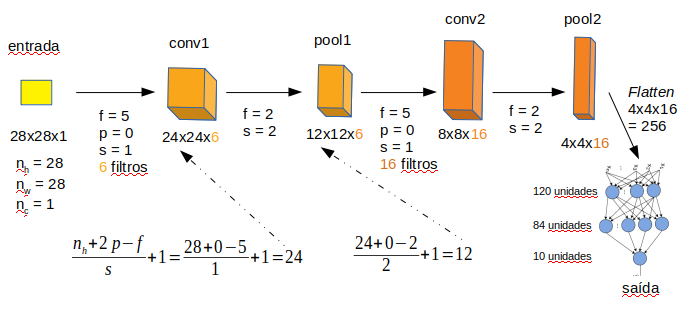

Neste exemplo, a rede neural será configurada como na figura acima. O modelo em Keras é definido como uma sequência de camadas. Em uma rede neural convolucional, a entrada tem 3 dimensões. Neste caso, as imagens têm tamanho 28 x 28, e estão em escala de cinza. Em Keras, é obrigatório o número de canais, neste caso, igual a 1 (camada *Input*).

A entrada passa por duas camadas de convolução + pooling, conforme os valores dos filtros de tamanho fxf, *stride* s e o número de filtros definidos para cada camada. Não é usado *padding* (p = 0). É comum que na configuração da rede convolucional, as duas primeiras dimensões vão diminuindo a cada camada, e a terceira dimensão vai aumentando (de acordo com o aumento do número de filtros usados). A camada de convolução pode manter as duas primeiras dimensões iguais, se for usado o mecanismo de *padding*. Já a camada de *pooling* tem como objetivo reduzir essas dimensões. Dessa forma, o número de elementos do vetor 1D a ser usado como entrada para a rede densa é menor do que o vetor 1D gerado se a imagem fosse usada diretamente como entrada para a rede densa.

Após a última camada de *pooling*, o vetor 3D é achatado (*flatten*) para gerar um vetor 1D, para ser usado como entrada para a rede densa. Em Keras, isso é feito pela camada *Flatten*. Essa camada cria um vetor de uma dimensão concatenando sequencialmente os valores no vetor de três dimensões gerado pela última camada de *pooling*. Desta forma, o vetor achatado terá dimensão (256, 1), o resultado de 4 x 4 x 16.

A rede densa é constituida de três camadas (*Dense layer*), conforme descrição do número de unidades de cada camada indicada na figura. A camada de saída tem dez unidades, cada uma representando um dos dígitos de 0 a 9, e usa a função *Softmax* para isso. É um problema de classificação multiclasse. 

Documentação: <br>
Keras: https://keras.io/ <br>
Classe *Model*: https://keras.io/api/models/model/ <br>
Classe *Sequential*:https://keras.io/api/models/sequential/#sequential-class <br>
Camadas: https://www.tensorflow.org/api_docs/python/tf/keras/layers <br>
Funções de ativação disponíveis: https://keras.io/api/layers/activations/ 

In [16]:
inputs = keras.Input(shape=(IMAGE_HEIGHT, IMAGE_WIDTH, IMAGE_CHANNELS))
x = keras.layers.Conv2D(filters=6, kernel_size=(5,5), padding='valid', strides=(1,1), activation ='relu')(inputs)
x = keras.layers.MaxPool2D(pool_size=(2,2), strides=(2,2))(x)
x = keras.layers.Conv2D(filters=16, kernel_size=(5,5), padding='valid', strides=(1,1), activation ='relu')(x)
x = keras.layers.MaxPool2D(pool_size=(2,2), strides=(2,2))(x)
x = keras.layers.Flatten()(x)
x = keras.layers.Dense(units=120, activation="relu")(x)
x = keras.layers.Dense(units=84, activation="relu")(x)
outputs = keras.layers.Dense(units=10, activation="softmax")(x)
model = keras.Model(inputs=inputs, outputs=outputs)  # instantiate a Model object

In [17]:
# Prints a summary of the network, showing its architecture and parameters.
model.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 28, 28, 1)]       0         
_________________________________________________________________
conv2d (Conv2D)              (None, 24, 24, 6)         156       
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 12, 12, 6)         0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 8, 8, 16)          2416      
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 4, 4, 16)          0         
_________________________________________________________________
flatten (Flatten)            (None, 256)               0         
_________________________________________________________________
dense (Dense)                (None, 120)               30840 

## Compilação do Modelo

Na compilação do modelo, a biblioteca de backend (TensorFlow, por exemplo) escolhe a melhor forma de representar a rede no seu hardware, tal como CPU, GPU ou TPU.

Os seguintes parâmetros devem ser especificados:
1. Loss Function – função de perda. No exemplo, será utilizada a função Categorical Cross-Entropy.
2. Optimizer – otimizador, o qual executa o algoritmo da descida do gradiente. Um dos otimizadores mais populares é o chamado de "rmsprop".
3. Metrics – métricas a serem monitoradas. Será usada a Acurácia.

Documentação: https://keras.io/api/models/model_training_apis/

In [18]:
model.compile(optimizer="rmsprop", loss="categorical_crossentropy", metrics=["accuracy"])

## Treinamento do Modelo

Ajusta o modelo aos dados de treinamento.
Devem ser fornecidos os dados de treinamento e o número de épocas (iterações). Uma época é composta por uma única passagem por todos os exemplos do conjunto de treino.

Documentação: https://keras.io/api/models/model_training_apis/

In [19]:
history = model.fit(train_generator, epochs = 3)  # history records what happened over the course of training
#print(history.history)  # print per-epoch timeseries of metrics values

Epoch 1/3
4000/4000 [==============================] - 43s 10ms/step - loss: 0.3037 - accuracy: 0.9033
Epoch 2/3
4000/4000 [==============================] - 38s 10ms/step - loss: 0.1182 - accuracy: 0.9647
Epoch 3/3
4000/4000 [==============================] - 45s 11ms/step - loss: 0.1007 - accuracy: 0.9720


## Visualização do Desempenho do Modelo

Exibe gráficos de performance do modelo treinado.

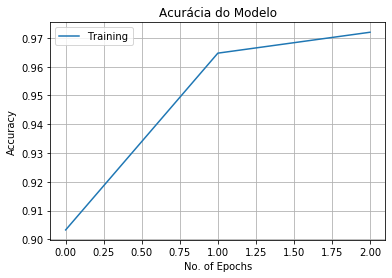

In [20]:
# plot the accuracy over the training set
plt.plot(history.history['accuracy'])
plt.title('Acurácia do Modelo')
plt.xlabel('No. of Epochs')
plt.ylabel('Accuracy')
plt.legend(['Training'])
plt.grid()
plt.show()

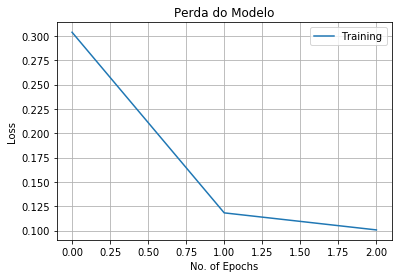

In [21]:
# plot the loss over the training set
plt.plot(history.history['loss'])
plt.title('Perda do Modelo')
plt.xlabel('No. of Epochs')
plt.ylabel('Loss')
plt.legend(['Training'])
plt.grid()
plt.show()

## Gravação do Modelo

O modelo treinado pode ser salvo em um arquivo para posterior reutilização.

Documentação: <br>
https://www.tensorflow.org/guide/keras/save_and_serialize <br>
https://keras.io/api/models/model_saving_apis/

In [22]:
model.save('modelo-mnist')

INFO:tensorflow:Assets written to: modelo-mnist/assets


In [23]:
# Carragendo o modelo de volta
#model = keras.models.load_model('modelo-mnist')

## Avaliação do Modelo

Avalia o desempenho da rede no conjunto de teste.

Documentação: https://keras.io/api/models/model_training_apis/

In [24]:
loss, acc = model.evaluate(X_test, Y_test)
print("Loss: %.4f" % loss, "\nAccuracy: %.4f" % acc)

313/313 [==============================] - 2s 6ms/step - loss: 0.0454 - accuracy: 0.9866
Loss: 0.0454 
Accuracy: 0.9866


## Predição

Prediz a saída de novos dados.

Documentação: <br>
Função *predict*: https://keras.io/api/models/model_training_apis/ <br>
Função *argmax*: https://numpy.org/doc/stable/reference/generated/numpy.argmax.html

Na classificação multiclasse, *model.predict* retorna um vetor de probabilidades para cada classe. A função *argmax* retorna o índice do vetor com a maior probabilidade, indicando assim a classe predita.

In [25]:
predictions = model.predict(X_test)
print("Predictions: ", [np.argmax(x, axis=-1) for x in predictions[:30]]) # print the first 30 predictions
print("\nCorrect:     ", [np.argmax(x, axis=-1) for x in Y_test[:30]])

Predictions:  [7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4, 9, 6, 6, 5, 4, 0, 7, 4, 0, 1]

Correct:      [7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4, 9, 6, 6, 5, 4, 0, 7, 4, 0, 1]


# Fim

Esses foram os passos para criação de uma rede neural convolucional para classificação de imagens.

-------------------------------------------